# BEE 4750 Homework 7: Mixed Integer Programming

**Name**: Anthony Santos

**ID**: acs367

> **Due Date**
>
> Thursday, 11/12/26, 9:00pm

## Overview

### Instructions

- Problem 1 asks you to formulate a wastewater plant’s choice of
  nitrogen upgrades with binary variables, then solve it in `JuMP`.
- Problem 2 asks you to solve a small integer program by hand with
  branch and bound.
- Write your answers in Markdown cells. For the sketches, a photo or
  scan of a hand drawing is fine: save it in this folder and insert it
  with `![](sketch.png)`.

### Load Environment

In [1]:
import Pkg
Pkg.activate(@__DIR__)
Pkg.instantiate()

  Activating project at `c:\Users\thean\Downloads\BEE 4750\HW7\hw07`


In [2]:
using JuMP
using HiGHS
using Plots

## Problems (Total: 50 Points)

### Problem 1 (30)

A city’s wastewater treatment plant discharges to an estuary where
nitrogen feeds algal blooms that leave the water low in oxygen each
summer. Its new permit requires it to remove at least 90 tonnes of
nitrogen per year (t N/yr) more than it does now. The plant already
converts the ammonia in its wastewater to nitrate. Its engineers have
shortlisted four upgrades:

- **Anoxic zones** turn part of the aeration basins into unaerated
  zones, where bacteria convert nitrate to nitrogen gas
  (**denitrification**) using carbon already in the wastewater.
- A **methanol feed** adds methanol to the anoxic zones, giving those
  bacteria extra carbon so they remove more nitrate.
- **Sidestream treatment** is a separate reactor that treats the
  ammonia-rich liquid pressed out of the plant’s digested sludge, before
  that liquid returns to the plant.
- A **denitrification filter** is a new filter at the end of the plant,
  where bacteria on the filter media remove nitrate from the effluent.

| Upgrade | Maximum removal (t N/yr) | Installation cost (\$1,000/yr) | Operating cost (\$/kg N removed) |
|:-----------------|-----------------:|-----------------:|-----------------:|
| Anoxic zones | 40 | 300 | 2 |
| Methanol feed | 40 | 20 | 5 |
| Sidestream treatment | 20 | 100 | 1 |
| Denitrification filter | 80 | 250 | 3 |

Installation costs are annualized: the construction cost is spread over
the life of the upgrade, so the installation cost is per year, like the
operating cost of a year’s removal. An upgrade that is installed costs
its full installation cost however much nitrogen it removes; one that is
not installed costs nothing and removes nothing.

There are two rules governing which combinations of upgrades are
allowed:

1.  The sidestream reactor and the filter would both be built on the
    plant’s one open site, which has room for only one of them (the
    **site rule**).
2.  The methanol feeds the bacteria in the anoxic zones, so the methanol
    feed can be installed only if the anoxic zones are (the **methanol
    rule**).

The plant wants to meet its removal requirement at the lowest annual
cost.

#### Problem 1.1 (4)

Define the decision variables, with units. Which are binary and which
are continuous?

Continuous variables: nitrogen removed by each upgrade 

Units: (t N/yr)

- $x_A$: anoxic zones, $0 \le x_A \le 40$
- $x_M$: methanol feed, $0 \le x_M \le 40$
- $x_S$: sidestream treatment, $0 \le x_S \le 20$
- $x_F$: denitrification filter, $0 \le x_F \le 80$

Binary variables: whether each upgrade is installed (dimensionless, $1$ = installed, $0$ = not)

- $y_A, y_M, y_S, y_F \in \{0, 1\}$

Binary vars will be multiplied by installation cost ($/year)

#### Problem 1.2 (10)

Write the objective function. Then write the permit constraint and one
constraint for each upgrade’s removal capacity.



Objective: minimize total annual cost ($1,000/yr)

$$
\min_{x,\,y} \ Z = 300\,y_A + 20\,y_M + 100\,y_S + 250\,y_F
 + 2\,x_A + 5\,x_M + 1\,x_S + 3\,x_F
$$

The operating coefficients carry over directly because of dimensional analysis from kg to tons

($\$$/kg N)(t N/yr)(1000 kg/t) $= 1000$ $\$$/yr $= 1$ ($\$1{,}000$/yr) per unit of $c \cdot x$.
So, for example, $2\,x_A$ is already in $\$1{,}000$/yr.

$s.t.$

Permit constraint: total removal must meet the 90 t N/yr requirement

$$
x_A + x_M + x_S + x_F \ge 90
$$

Capacity constraints: each upgrade removes at most its maximum, and nothing if it is not installed (t N/yr)

$$
\begin{aligned}
x_A &\le 40\,y_A \\
x_M &\le 40\,y_M \\
x_S &\le 20\,y_S \\
x_F &\le 80\,y_F
\end{aligned}
$$

with $x_A, x_M, x_S, x_F \ge 0$.


#### Problem 1.3 (6)

Write the site rule and the methanol rule as one linear constraint each.

Site rule: at most one of the sidestream reactor and the filter can be built

$$
y_S + y_F \le 1
$$

Methanol rule: the methanol feed can be installed only if the anoxic zones are

$$
y_M \le y_A
$$

#### Problem 1.4 (10)

Implement your model in `JuMP` and solve it with `HiGHS`. Report which
upgrades are installed, how much each removes, and the annual cost.

In [ ]:
# Upgrades in the order: anoxic zones, methanol feed, sidestream, filter
upgrade_names = ["Anoxic zones", "Methanol feed", "Sidestream treatment", "Denitrification filter"]
max_removal = [40, 40, 20, 80]            # [t N/yr]
installation_cost = [300, 20, 100, 250]   # [$1,000/yr]
operating_cost = [2, 5, 1, 3]             # [$/kg N]
required_removal = 90                     # [t N/yr]

nitrogen = Model(HiGHS.Optimizer)
set_silent(nitrogen)

# Add the variables, the objective, the permit and linking constraints,
# and the two rules.
@variable(nitrogen, x[1:4] >= 0) # removal [t N/yr]
@variable(nitrogen, y[1:4], Bin) # 1 or 0

# Objective Function
@objective(nitrogen, Min, sum(1000 * installation_cost[i] * y[i] + 1000 * operating_cost[i] * x[i] for i in 1:4))

# Constraints
@constraint(nitrogen, permit, sum(x) >= required_removal)
@constraint(nitrogen, capacity[i in 1:4], x[i] <= max_removal[i] * y[i])
@constraint(nitrogen, site_rule, y[3] + y[4] <= 1)
@constraint(nitrogen, methanol_rule, y[2] <= y[1])

optimize!(nitrogen)

# Report results
println("Status: ", termination_status(nitrogen))
println("Anoxic zones: installed = ", round(Int, value(y[1])), ", removal = ", round(value(x[1]), digits=1), " t N/yr")
println("Methanol feed: installed = ", round(Int, value(y[2])), ", removal = ", round(value(x[2]), digits=1), " t N/yr")
println("Sidestream treatment: installed = ", round(Int, value(y[3])), ", removal = ", round(value(x[3]), digits=1), " t N/yr")
println("Denitrification filter: installed = ", round(Int, value(y[4])), ", removal = ", round(value(x[4]), digits=1), " t N/yr")
println("Annual cost: \$", round(objective_value(nitrogen), digits=0), "/yr")

Status: OPTIMAL
Anoxic zones: installed = 1, removal = 40.0 t N/yr
Methanol feed: installed = 1, removal = 30.0 t N/yr
Sidestream treatment: installed = 1, removal = 20.0 t N/yr
Denitrification filter: installed = 0, removal = -0.0 t N/yr
Annual cost: $670000.0/yr


### Problem 2 (20)

A water utility must add ultraviolet (UV) disinfection to its
drinking-water plant, as a second barrier against *Cryptosporidium*. It
can buy two kinds of UV reactor:

| Reactor         | Capacity (MGD) | Price (\$100,000) | Power (kW) |
|:----------------|---------------:|------------------:|-----------:|
| Medium-pressure |              5 |                 2 |         10 |
| Low-pressure    |              2 |                 1 |          2 |

Medium-pressure reactors cost less per MGD of capacity, and low-pressure
reactors use less power per MGD. A state grant covers \$1,000,000 of
reactors, and the UV building’s electrical service has 41 kW to spare.
The utility wants as much UV capacity, in million gallons per day (MGD),
as the grant and the power supply allow. With $x_1$ medium-pressure and
$x_2$ low-pressure reactors, the problem is

$$\begin{aligned}
\max_{x_1, x_2} \quad & z = 5x_1 + 2x_2 && \text{(MGD)} \\
\text{subject to:} \quad & 2x_1 + x_2 \leq 10 && \text{(grant, \$100,000)} \\
& 10x_1 + 2x_2 \leq 41 && \text{(power, kW)} \\
& x_1, x_2 \geq 0, \ \text{integer}.
\end{aligned}$$

Solve it by branch and bound, by hand.

#### Problem 2.1 (7)

Node 1 is the LP relaxation: the same problem without the integer
requirement. Sketch its feasible region with $x_1$ on the horizontal
axis, label each corner with its coordinates, and find node 1’s LP
optimum and its $z$. Is that $z$ an upper or a lower bound on the best
capacity the utility can actually buy? Why?



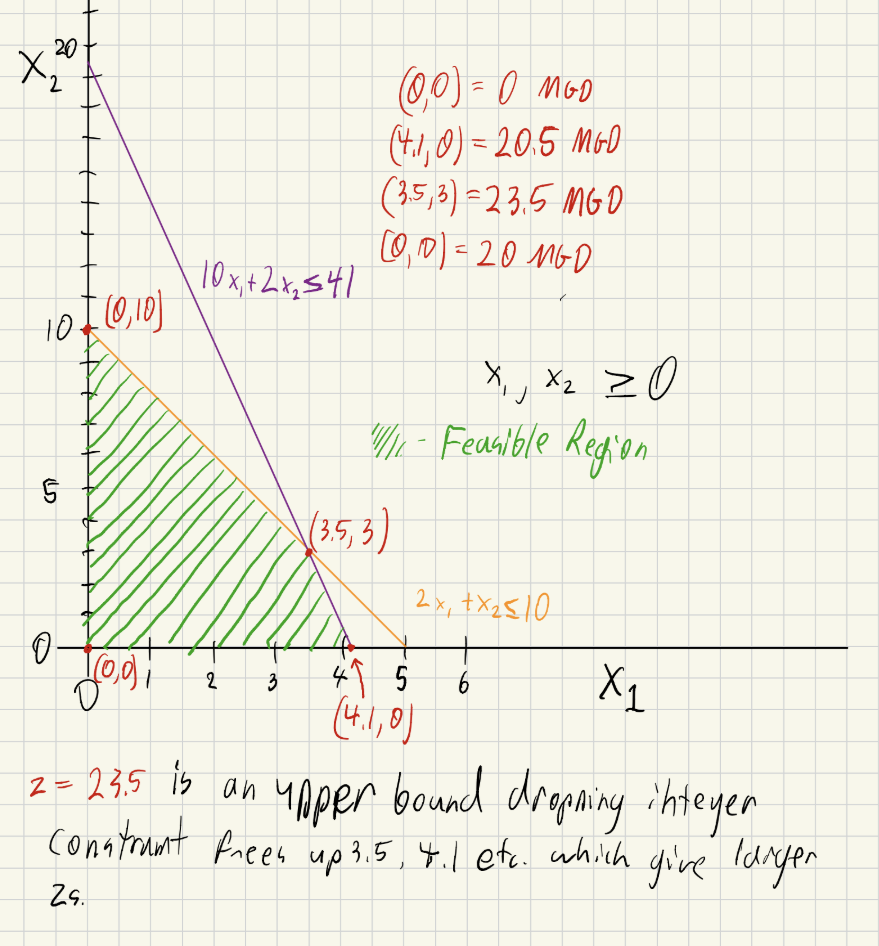

#### Problem 2.2 (13)

Branch on $x_1$: node 2 adds $x_1 \leq 3$, and node 3 adds $x_1 \geq 4$.
Solve the LP at each node (a sketch with its corners is enough), and
report each solution and its $z$. Which node(s) can be pruned, and by
which rule? What is the best purchase, and its capacity?

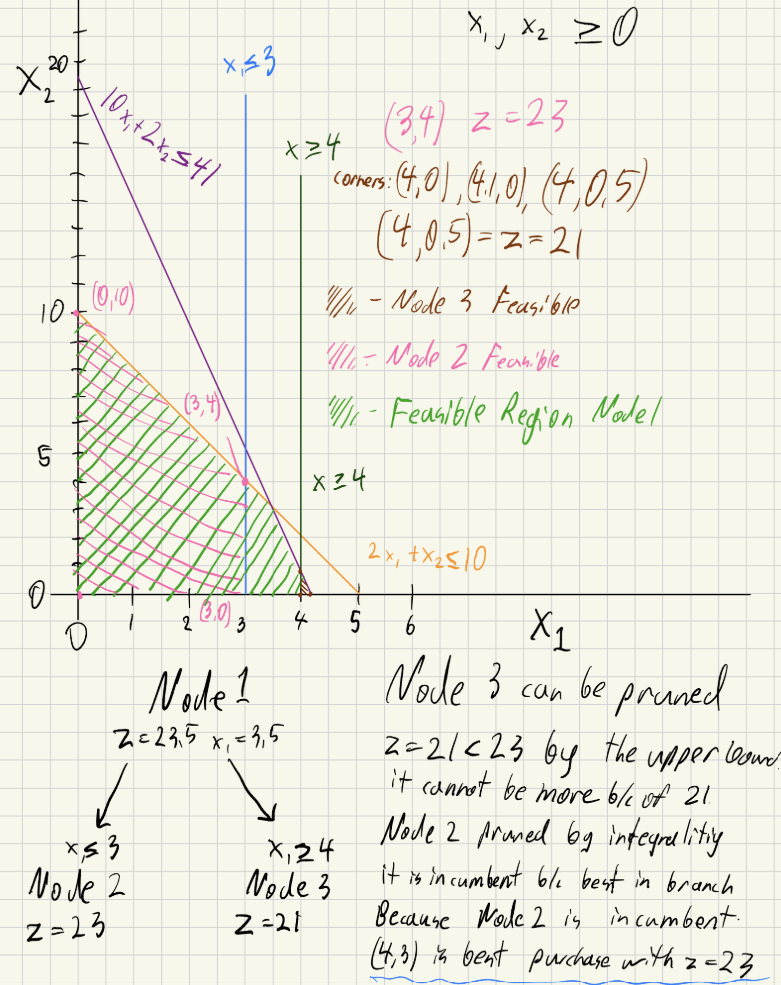